# Dense indoor radio-map evaluation (M3 / M4 gaps)

Runs on top of your existing `rmbench_*.py` modules via `run_indoor_dense.py`. **All outputs stay in this notebook** (tables, logs, figures), and the raw results are also written to `results_dense/*.jsonl` and `*.csv`.

Place this notebook in the same folder as `rmbench_core.py`, `rmbench_nn.py`, `rmbench_ext.py`, `rmbench_ext2.py`, `rmbench_ext3.py`, `rmbench_dmfix.py`, `run_ext.py` and `run_indoor_dense.py`.

**Run order:** 0 setup → 1 UJI diagnosis → 2 (optional) finish UJI run → 3 freeze plan → 4 smoke test → 5 wall → 6 DeepMIMO → 7 figures.
Restart the kernel before the first run (modules are imported once). Every long run is resumable: re-running a cell skips finished tasks.

**Cache gotcha:** if you change the job list or the code of a method, change the `TAG_SUFFIX` below; otherwise finished task ids silently skip the new method.

In [1]:
# 0. Setup ------------------------------------------------------------------------------------------------------------
import os, sys, glob, hashlib, importlib
sys.path.insert(0, os.getcwd())
need = ["rmbench_core","rmbench_nn","rmbench_ext","rmbench_ext2","rmbench_ext3","rmbench_dmfix","run_ext","run_indoor_dense"]
missing = [m for m in need if not os.path.exists(m + ".py")]
assert not missing, f"missing files next to the notebook: {missing}"

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rmbench_core as rc, rmbench_ext as rx, rmbench_ext2 as r2
import run_indoor_dense as rd
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

N_JOBS    = max(1, (os.cpu_count() or 2) - 1)   # worker processes
MAX_UNITS = 24                                    # DeepMIMO: units kept per scenario
TAG_SUFFIX = ""                                   # change (e.g. "_v2") if you edit job lists, see note above
print("cpus:", os.cpu_count(), "| n_jobs:", N_JOBS)
print("densities:", rd.DENSITIES, "| n_rep:", rd.N_REP, "| n_test:", rd.DENSE_CFG["n_test"], "| primary coverage metric:", rd.COV_PRIMARY)
print("wall spec:", rd.WALL_SPEC, "| DeepMIMO scenarios:", rd.DM_SCENARIOS)

cpus: 16 | n_jobs: 15
densities: (50, 100, 200, 300) | n_rep: 5 | n_test: 200 | primary coverage metric: bacc_q25
wall spec: {'n_layouts': 12, 'n_tx': 6, 'n_pts': 1000, 'seed': 7} | DeepMIMO scenarios: ('i1_2p5', 'i2_28b', 'i3_60')


## 1. UJI diagnosis
Shows what the saved UJI result files contain per building (is `b1` missing? any failures?) and how many units in the raw data could carry 100 / 150 / 200 labels. Needs `data/ujiindoorloc` (downloaded automatically if the network is open).

In [2]:
rd.diagnose_uji()

=== 1. what the saved UJI result files contain

 results_ext_uji/uji_grid.jsonl
        rows   ok  units  parents
layout                           
uji_b0   702  702      6        1
  densities: [np.int64(15), np.int64(30), np.int64(60)]  methods: 9

 results_ext_uji/uji_grid_blocked.jsonl
        rows   ok  units  parents
layout                           
uji_b0   945  945      7        1
uji_b2   810  810      6        1
  densities: [np.int64(15), np.int64(30), np.int64(60)]  methods: 9

 results_ext_uji/uji_lolo_blocked.jsonl
        rows    ok  units  parents
layout                            
uji_b0  1050  1050      7        1
uji_b2   900   900      6        1
  densities: [np.int64(15), np.int64(30), np.int64(60)]  methods: 10

=== 2. what the raw UJI csv could support (needs data/ujiindoorloc)
        units  floors  pts_min  pts_median  pts_max
layout                                             
uji_b0      7       1      114       122.0      153
uji_b2      6       1      115

## 2. (Optional) Finish the UJI run
Runs your existing `run_ext.py uji` and streams its output into this notebook. It is **resumable**. This can take a long time; run the random split first, then the blocked split. Skip this section if you only want the dense run.

In [3]:
import subprocess
def stream(cmd):
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout: print(line, end="")
    return p.wait()

RUN_UJI_RANDOM = False      # set True to run
if RUN_UJI_RANDOM:
    print("exit code:", stream([sys.executable, "run_ext.py", "uji", "--n-jobs", str(N_JOBS)]))

In [4]:
RUN_UJI_BLOCKED = False     # set True to run
if RUN_UJI_BLOCKED:
    print("exit code:", stream([sys.executable, "run_ext.py", "uji", "--blocked", "--n-jobs", str(N_JOBS)]))

## 3. Freeze the plan
Writes `results_dense/prereg_dense.json` and its sha256. **Commit it to git before section 5.** It refuses to overwrite an existing plan. `run` refuses to start without it.

In [5]:
if os.path.exists(rd.PREREG):
    print("already frozen:", rd.PREREG, open(rd.PREREG + ".sha256").read().strip())
else:
    rd.freeze()
print(open(rd.PREREG).read())

already frozen: results_dense/prereg_dense.json 06ca69ef5095b09827bf3aeb12257ec1e4cde86ab1420579c0955a965a790184
{
  "written": "2026-10-21T15:49:14",
  "question": "Do GCN/GAT beat IDW / kriging (and rk_side where side information exists) on DENSE (200, 300) and sparse (50, 100) labels on indoor layouts?",
  "densities": [
    50,
    100,
    200,
    300
  ],
  "n_rep": 5,
  "n_test": 200,
  "test_salt": "dense1",
  "wall": {
    "n_layouts": 12,
    "n_tx": 6,
    "n_pts": 1000,
    "seed": 7,
    "cfg_cache": "cache_dense_wall"
  },
  "dm_scenarios": [
    "i1_2p5",
    "i2_28b",
    "i3_60"
  ],
  "coverage_metric": {
    "primary": "bacc_q25",
    "threshold": "25th percentile of train labels",
    "secondary": [
      "acc_q25",
      "within5",
      "area_q25"
    ]
  },
  "jobs_wall": [
    "trend",
    "idw",
    "krig_global",
    "kgnn",
    "gcn_knn",
    "gcn_del",
    "gat_knn",
    "gat_del",
    "gcn_knn_side",
    "gat_del_side",
    "rk_side"
  ],
  "jobs_dm": [
  

## 4. Smoke test (plumbing only, says nothing about science)
Four small wall layouts, 15 training steps. If this fails, stop and fix it before the real runs.

In [6]:
import shutil
shutil.rmtree("dense_smoke", ignore_errors=True)
_out = rd.OUT
cfg = dict(rd.WALL_CFG, cache_dir="dense_smoke/cache", densities=(30, 60, 120), n_rep=2, n_test=60, min_unit_points=300)
ok = r2.build_wall_units(cfg, n_layouts=4, n_tx=2, seed=0, n_pts=400)
tasks = r2.make_tasks2(ok, cfg["densities"], range(cfg["n_rep"]), rd.jobs_for("wall", steps=15), cfg, prefix="smoke")
rd.run_tasks_dense(tasks, "dense_smoke/smoke.jsonl", n_jobs=1)
df_smoke = rc.read_results("dense_smoke/smoke.jsonl")
rd.OUT = "dense_smoke"
rd.report(df_smoke, "wall", "smoke", cap=rd.cap_for("wall", 1))
rd.OUT = _out
print("\nfailed rows:", int((df_smoke.status != "ok").sum()), "of", len(df_smoke))

[run_tasks_dense] 48 tasks, 0 done, 48 to run (n_jobs=1) -> dense_smoke/smoke.jsonl
  25/48 18s failed jobs: 0
  48/48 32s failed jobs: 0

##### smoke: 528 job rows, 528 ok, 0 failed
parents per scenario (inference needs >= 6): {'wall': 4} -> inferential: []

=== rmse (lower is better), parent-level mean
name              gat_del  gat_del_side  gat_knn  gcn_del  gcn_knn  gcn_knn_side    idw   kgnn  krig_global  rk_side  trend
scenario density                                                                                                           
wall     30         5.561         5.173    5.617    5.849    5.888         5.672  5.144  5.029        5.126    4.143  6.217
         60         5.065         4.840    5.227    5.195    5.131         5.222  4.774  4.697        4.652    3.655  6.081
         120        4.736         4.479    4.751    5.118    4.871         4.743  4.357  4.241        4.294    3.302  6.027

=== bacc_q25 (higher is better), parent-level mean
name              gat_

## 5. Dense indoor run: wall simulator
12 layouts × 6 transmitters × 1000 points, densities 50 / 100 / 200 / 300, with side-information methods. Resumable.

In [7]:
rd.require_prereg()
os.makedirs(rd.OUT, exist_ok=True)
kind = "wall"; tag = f"dense_{kind}{TAG_SUFFIX}"; path = f"{rd.OUT}/{tag}.jsonl"; cfg = rd.WALL_CFG
units = rd.feasible(rd.build_wall(cfg), cfg)
tasks = r2.make_tasks2(units, cfg["densities"], range(cfg["n_rep"]), rd.jobs_for(kind), cfg, prefix=tag)
print(len(units), "units,", len(tasks), "tasks")
rd.run_tasks_dense(tasks, path, n_jobs=N_JOBS)

72 units, 1440 tasks
[run_tasks_dense] 1440 tasks, 990 done, 450 to run (n_jobs=15) -> results_dense/dense_wall.jsonl
  25/450 46s failed jobs: 0
  50/450 73s failed jobs: 0
  75/450 103s failed jobs: 0
  100/450 139s failed jobs: 0
  125/450 168s failed jobs: 0
  150/450 198s failed jobs: 0
  175/450 224s failed jobs: 0
  200/450 259s failed jobs: 0
  225/450 287s failed jobs: 0
  250/450 317s failed jobs: 0
  275/450 348s failed jobs: 0
  300/450 377s failed jobs: 0
  325/450 407s failed jobs: 0
  350/450 438s failed jobs: 0
  375/450 472s failed jobs: 0
  400/450 505s failed jobs: 0
  425/450 534s failed jobs: 0
  450/450 557s failed jobs: 0


In [8]:
df_wall = rc.read_results(f"{rd.OUT}/dense_wall{TAG_SUFFIX}.jsonl")
rd.report(df_wall, "wall", f"dense_wall{TAG_SUFFIX}", cap=rd.cap_for("wall", df_wall[df_wall.status == "ok"].scenario.nunique()))


##### dense_wall: 15840 job rows, 15840 ok, 0 failed
parents per scenario (inference needs >= 6): {'wall': 12} -> inferential: ['wall']

=== rmse (lower is better), parent-level mean
name              gat_del  gat_del_side  gat_knn  gcn_del  gcn_knn  gcn_knn_side    idw   kgnn  krig_global  rk_side  trend
scenario density                                                                                                           
wall     50         5.918         5.076    5.854    5.910    5.886         5.412  5.392  5.223        5.302    4.143  7.689
         100        5.196         4.448    5.140    5.226    5.142         4.820  4.757  4.629        4.699    3.709  7.584
         200        4.636         3.921    4.583    4.696    4.626         4.367  4.253  4.132        4.211    3.367  7.525
         300        4.312         3.689    4.308    4.420    4.354         4.186  3.978  3.850        3.944    3.189  7.519

=== bacc_q25 (higher is better), parent-level mean
name              ga

## 6. Dense indoor run: DeepMIMO (`i1_2p5`, `i2_28b`, `i3_60`)
Needs DeepMIMO and network access on first run. A scenario the installed DeepMIMO does not know (e.g. an unverified `i3_60` slug) is printed as *dropped*, not fatal. Only scenarios with >= 6 transmitters get paired tests; the rest are descriptive.

In [9]:
rd.require_prereg()
kind = "dm"; tag = f"dense_{kind}{TAG_SUFFIX}"; path = f"{rd.OUT}/{tag}.jsonl"; cfg = rd.DM_CFG
units = rd.feasible(rd.build_dm(cfg, max_units=MAX_UNITS), cfg)
tasks = r2.make_tasks2(units, cfg["densities"], range(cfg["n_rep"]), rd.jobs_for(kind), cfg, prefix=tag)
print(len(units), "units,", len(tasks), "tasks")
rd.run_tasks_dense(tasks, path, n_jobs=N_JOBS)

Scenario "i1_2p5" already exists in /home/praaneshnair/gitProjects/prism/deepmimo_scenarios
Loading TXRX PAIR: TXset 2 (tx_idx 0) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 1) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 2) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 3) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 4) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 5) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 6) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 7) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 8) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 9) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 10) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 11) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 12) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXset 2 (tx_idx 13) & RXset 0 (rx_idxs 3000)
Loading TXRX PAIR: TXs

In [10]:
df_dm = rc.read_results(f"{rd.OUT}/dense_dm{TAG_SUFFIX}.jsonl")
rd.report(df_dm, "dm", f"dense_dm{TAG_SUFFIX}", cap=rd.cap_for("dm", df_dm[df_dm.status == "ok"].scenario.nunique()))


##### dense_dm: 4320 job rows, 4320 ok, 0 failed
parents per scenario (inference needs >= 6): {'i1_2p5': 24, 'i2_28b': 1, 'i3_60': 2} -> inferential: ['i1_2p5']

=== rmse (lower is better), parent-level mean
name              gat_del  gat_knn  gcn_del  gcn_knn    idw   kgnn  krig_global  trend
scenario density                                                                      
i1_2p5   50         0.099    0.100    0.099    0.101  0.089  0.082        0.083  0.160
         100        0.083    0.083    0.084    0.083  0.075  0.071        0.071  0.155
         200        0.068    0.069    0.071    0.069  0.063  0.060        0.061  0.152
         300        0.062    0.063    0.064    0.063  0.058  0.054        0.056  0.152
i2_28b   50         0.943    0.943    0.922    0.983  0.832  0.847        0.836  1.413
         100        0.852    0.832    0.888    0.881  0.734  0.736        0.750  1.400
         200        0.712    0.711    0.765    0.700  0.633  0.591        0.675  1.402
        

## 7. Figures and summary
RMSE and the primary coverage metric (`bacc_q25`) against label density, per scenario. Saved to `results_dense/figures/` and shown here.

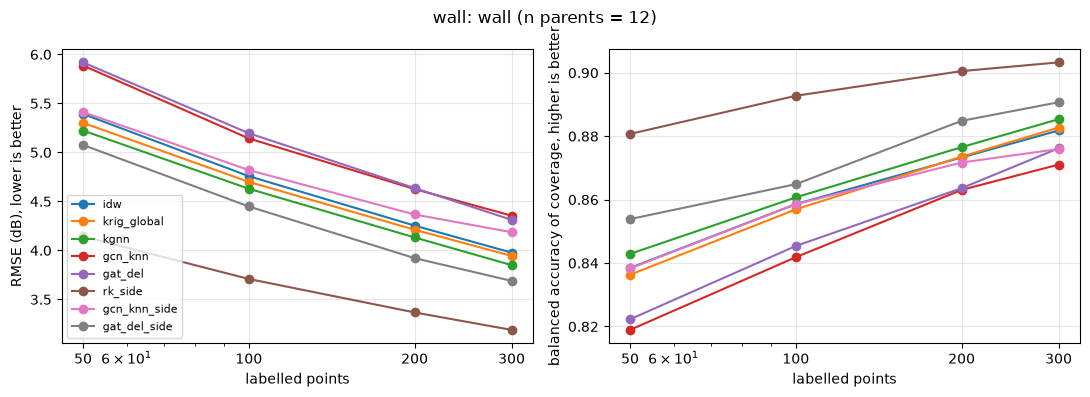

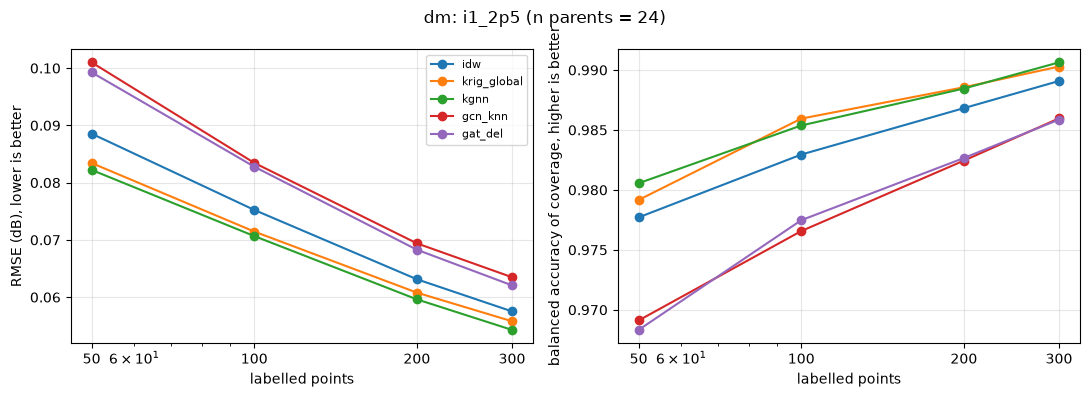

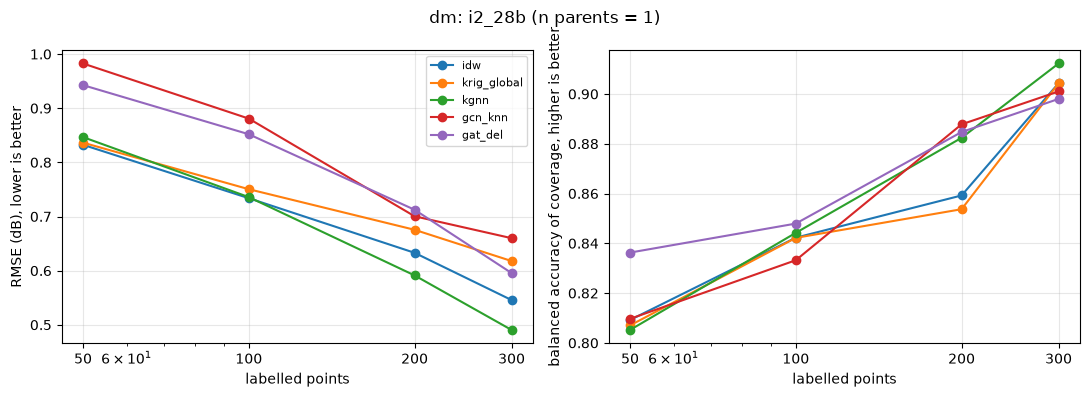

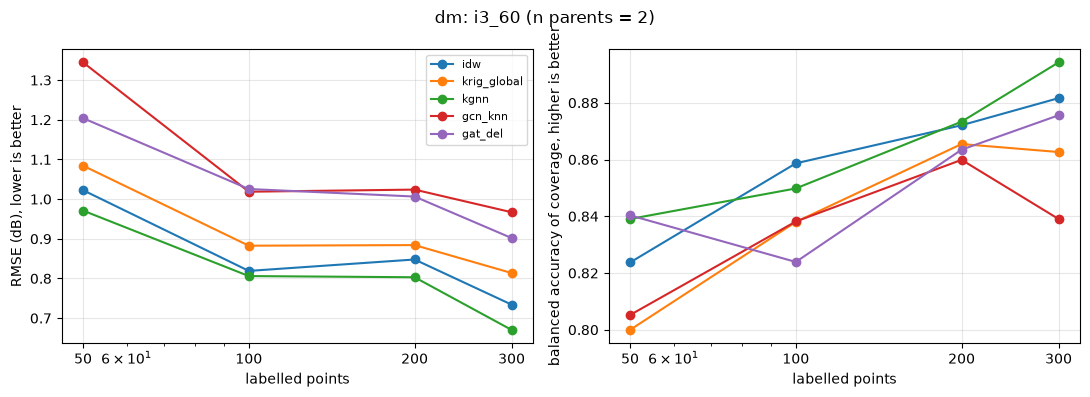

In [11]:
os.makedirs(f"{rd.OUT}/figures", exist_ok=True)
SHOW = ["idw", "krig_global", "kgnn", "gcn_knn", "gat_del", "rk_side", "gcn_knn_side", "gat_del_side"]

def curves(df, tag):
    ok = df[df.status == "ok"]
    for scen in sorted(ok.scenario.unique()):
        d = ok[ok.scenario == scen]
        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        for a, col, lab in [(ax[0], "rmse", "RMSE (dB), lower is better"), (ax[1], rd.COV_PRIMARY, "balanced accuracy of coverage, higher is better")]:
            if col not in d: continue
            t = rx.agg_metric(d, col)
            t = t.droplevel(0) if t.index.nlevels > 1 else t
            for m in [m for m in SHOW if m in t.columns]:
                a.plot(t.index, t[m], marker="o", label=m)
            a.set_xlabel("labelled points"); a.set_ylabel(lab); a.set_xscale("log"); a.set_xticks(list(t.index)); a.set_xticklabels(list(t.index)); a.grid(alpha=.3)
        ax[0].legend(fontsize=8); fig.suptitle(f"{tag}: {scen} (n parents = {d.parent.nunique()})")
        fig.tight_layout(); fig.savefig(f"{rd.OUT}/figures/{tag}_{scen}.png", dpi=150); plt.show()

for nm in ("df_wall", "df_dm"):
    if nm in globals(): curves(globals()[nm], nm[3:])

In [12]:
# one combined table: mean RMSE and coverage metric per scenario / density / method (parent-level means)
frames = []
for nm in ("df_wall", "df_dm"):
    if nm in globals():
        d = globals()[nm]
        for col in ("rmse", rd.COV_PRIMARY, "within5"):
            if col in d:
                t = rx.agg_metric(d, col).stack().rename(col); frames.append(t)
if frames:
    summary = pd.concat(frames, axis=1).round(3); summary.to_csv(f"{rd.OUT}/summary_dense.csv"); display(summary)

rmse  bacc_q25  within5   rmse  bacc_q25  within5
scenario density name                                                            
wall     50      gat_del       5.918     0.822    0.621    NaN       NaN      NaN
                 gat_del_side  5.076     0.854    0.692    NaN       NaN      NaN
                 gat_knn       5.854     0.820    0.625    NaN       NaN      NaN
                 gcn_del       5.910     0.815    0.621    NaN       NaN      NaN
                 gcn_knn       5.886     0.819    0.624    NaN       NaN      NaN
...                              ...       ...      ...    ...       ...      ...
i3_60    300     gcn_knn         NaN       NaN      NaN  0.967     0.839    0.990
                 idw             NaN       NaN      NaN  0.734     0.882    0.995
                 kgnn            NaN       NaN      NaN  0.670     0.894    0.994
                 krig_global     NaN       NaN      NaN  0.814     0.863    0.992
                 trend           NaN       NaN      NaN  1.261     0.693    0.990

[140 rows x 6 columns]